# Mask R-CNN - Train on particles dataset


This notebook shows how to train Mask R-CNN sequentially so that one can train starting with synthetic data, then retrain models on manual segmentations for better performance. 

Note that work has been adapted and extends upon the "train_shapes" sample from [matterport's Mask RCNN release](https://github.com/matterport/Mask_RCNN).

# Table of contents
[1. Environment Initialization and Setup](#1-environment-initialization-and-setup)
   - [1.1 Configuration](#11-configuration)

[2. Loading Datasets](#2-loading-datasets)

[3. Training Procedure](#3-training-procedure)
   - [3.1 Model Initialization](#31-model-initialization)
   - [3.2 Dataset Selection & Training Schedule](#32-dataset-selection--training-schedule)
   - [3.3 Define custom callbacks](#33-define-custom-callbacks)
   - [3.4 Data Augmentation](#34-data-augmentation)
   - [3.5 Run training through schedule](#35-run-training-through-schedule)

[4. Fine-tuning on Manual Images](#4-fine-tuning-on-manual-images)


# 1. Environment Initialization and Setup

This cell prepares the runtime environment and project structure for evaluating our models:

- **GPU Selection and Logging**
    - `os.environ["CUDA_VISIBLE_DEVICES"]`: choose which GPU to use for this notebook (here, GPU 0). This allows us to run the notebook while other notebooks (such as SAGE_train) run on other GPUs.
    - `os.environ["TF_CPP_MIN_LOG_LEVEL"]`: suppress TensorFlow info/warning messages
    - `warnings.filterwarnings("ignore", message=".Model.state_updates.*")`: suppresses warnings related to state updates for cleaner output


It also sets various directories that need to be accessed throughout the notebook, as well as handles necessary package imports

At the end of the cell, the code will determine whether the SAGE pretrained models are available (and found in the `pretrained_models` directory). If they have not yet been downloaded, they will be downloaded and extracted from the corresponding release. 

The initial coco weights are also downloaded. 

In [1]:
import os
import warnings
import sys
# Set which GPU to use dynamically (e.g., "4" for GPU 4)
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
# Suppress WARNING and INFO logs, shows only ERRORs
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   

#Supress model state warnings

warnings.filterwarnings("ignore", message=".*Model.state_updates.*")


import tensorflow as tf
# Uncomment for debugging/TF build
# print("TensorFlow version:", tf.__version__)
# print("Built with CUDA:", tf.test.is_built_with_cuda())
# print("GPU Available:", tf.config.list_physical_devices('GPU'))

#==============================================================
# CORE Libraries
#==============================================================

import math
from tqdm.notebook import tqdm
from IPython.display import clear_output

#==============================================================
#  PROJECT DIRECTORIES
#==============================================================

# Root directory of the project
ROOT_DIR = os.path.abspath("../SAGE-fork")
print("ROOT DIR:", ROOT_DIR)

#Subdirectores:
PRETRAIN_DIR = os.path.join(ROOT_DIR,"pretrained_models") #Pretrained models folder, where models already trained (by us) are stored
MODEL_DIR = os.path.join(ROOT_DIR, "logs") # Directory to save logs and trained model
Results_DIR = os.path.join(ROOT_DIR, "Results") # Directory to save results (images, etc)
Dataset_DIR = os.path.join(ROOT_DIR, "data") # Directory to save datasets (images, etc)


print("Dataset Directory:", Dataset_DIR)
print("PRETRAINED MODELS DIRECTORY:", PRETRAIN_DIR)
print("MODEL DIRECTORY:", MODEL_DIR)
print("Results DIR:", Results_DIR)


#==============================================================
#  MASK RCNN SETUP
#==============================================================

# Import Mask RCNN
sys.path.append(ROOT_DIR)  # To find local version of the library
from mrcnn.config import Config, SAGEConfig
from mrcnn import utils
import mrcnn.model as modellib
from mrcnn import visualize
from mrcnn.model import log
from mrcnn.utils import print_verbose

mrcnn_dir = os.path.dirname(modellib.__file__)
model_file_path = os.path.join(mrcnn_dir,'model.py')
print("mrcnn directory:",mrcnn_dir)
print("Path to model.py:", model_file_path)


#Check if pretrained models are available
if not os.path.exists(PRETRAIN_DIR):
   utils.download_pretrained_models(ROOT_DIR)

#ENSURE COCO weights are available
COCO_MODEL_PATH = os.path.join(PRETRAIN_DIR, "mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
   utils.download_trained_weights(COCO_MODEL_PATH)
    
print("COCO MODEL PATH:", COCO_MODEL_PATH)




utils.download_datasets(Dataset_DIR, force=False, test_mode=False)

#import callbacks
from mrcnn.callbacks import MeanAveragePrecisionCallback
from mrcnn.callbacks import TrainingLogger

# Print out some useful info about the environment --- IGNORE ---
#print("sys.prefix:",sys.prefix)
#print("sys.executable:",sys.executable)
#print("sys.path:", sys.path)
%matplotlib inline 


#import tensorboard stuff
%load_ext tensorboard




2026-10-30 13:00:12.029966: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


ROOT DIR: /home/gventera/SAGE-fork
Dataset Directory: /home/gventera/SAGE-fork/data
PRETRAINED MODELS DIRECTORY: /home/gventera/SAGE-fork/pretrained_models
MODEL DIRECTORY: /home/gventera/SAGE-fork/logs
Results DIR: /home/gventera/SAGE-fork/Results
Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
mrcnn directory: /home/gventera/SAGE_TPD/mrcnn
Path to model.py: /home/gventera/SAGE_TPD/mrcnn/model.py
COCO MODEL PATH: /home/gventera/SAGE-fork/pretrained_models/mask_rcnn_coco.h5
Dataset already exists. Skipping download.


## 1.1 Configuration

This work uses a subclass of the base `Config` called `SAGEConfig` that is imported from `config.py`. This can be further subclassed to locally override any configuration or training parameters within the notebook. Some possible options to be changed are included below, but currently reflect the default values. Other options can be found in `config.py`

In [2]:
class TrainConfig(SAGEConfig): #instantiate to check for errors in config definition
    
    GPU_COUNT = 1
    IMAGES_PER_GPU = 2

    IMAGE_RESIZE_MODE = "square"
    IMAGE_MIN_DIM = 1024
    IMAGE_MAX_DIM =  1024

    RPN_ANCHOR_SCALES = (32, 64, 128, 256,512)#(16,32,64,128,256)# #(16,32,64,128,256)#  # anchor side in pixels
                 #opt to change to smaller values to recognize smaller particles as well

    TRAIN_ROIS_PER_IMAGE = 256 #increase from 128 to 256 to generate more ROIs
    DETECTION_MAX_INSTANCES = 200 #increase from 100 to 200

    #non-maximum suppression threshold for detection
    DETECTION_MIN_CONFIDENCE = 0.7

    #EARLY STOPPING
    EARLY_STOPPING_MONITOR = 'val_loss'
    EARLY_STOPPING_PATIENCE = 10 #number of epochs with no improvement required to stop
    ES_RESTORE_BEST_WEIGHTS =True
    ES_MODE= "min"
    ES_VERBOSE = 0

    LOSS_WEIGHTS = {
        "rpn_class_loss": 1.,
        "rpn_bbox_loss": 1.,
        "mrcnn_class_loss": 1.,
        "mrcnn_bbox_loss": 1.,
        "mrcnn_mask_loss": 1.,
    }
    
config = TrainConfig()


# 2. Loading Datasets

Here, we load the image sets that will be used for training and validation. Multiple datasets can be loaded to facilitate easy access and transfer learning. We load them using an extended dataset class called SAGE_Dataset.

Each dataset is defined using a tuple containing:
1. `dataset_name` - Name of dataset to load.
2. `use_results` - Whether to create associated results directories
3. `load_particles` - Load primary particle masks
4. `load_clusters` - Load aggregate cluster masks
5. `load_cluster_as_input` - Load cluster masks as auxiliary inputs for models trained using cluster-aware pipeline (experimental, not fully active in current release)

In this example, we focus on training and fine-tuning using real annotated TEM images. 

Synthetic datasets used for training SAGE<sub>0</sub> are not currently required for this notebook execution and will be included in the future.

* `Final_Trainv1_norm`, `Final_Valv1_norm`: real TEM images annotated manually for training a second model (SAGE<sub>1-exp-N</sub>) to fine tune SAGE<sub>0</sub>. These images have been preprocessed to ensure consistent nm/pixel scale across all images (See `SAGE_PREPROCESS.ipynb`).


Since these datasets are used in training only, we set `use_results=False` so that no results directories are created.


In [3]:
#List of tuples: (dataset_name, use_results, load_particles, load_clusters, load_cluster_as_input=False)


datasets_to_load= [
 
    # datasets for fine tuning with real TEM images
    ('Final_Trainv1_norm', False, True, False, False),
    ('Final_Valv1_norm', False, True, False, False),

 
]
datasets = {}


for idx, (name, use_results, load_particles, load_clusters, load_cluster_as_input) in enumerate(datasets_to_load, start=1):
    clear_output(wait=True)
    pbar_datasets = tqdm(total=len(datasets_to_load), desc="Loading datasets", dynamic_ncols=True, position=0, leave=True, initial=idx-1,bar_format="{l_bar}{bar} {n_fmt}/{total_fmt}")

    datasets[name] = utils.load_and_register_dataset(name,ROOT_DIR, Results_DIR,
                                                     load_particle=load_particles, load_cluster= load_clusters,
                                                     load_cluster_as_input=load_cluster_as_input, create_dirs=use_results)
   
    pbar_datasets.update(1)
   


Loading datasets:  50%|#####      1/2

Loading masks for Final_Valv1_norm:   0%|          | 0/18 [00:00<?, ?it/s]

Next, we can double check that masks are correctly assigned for each dataset. For each dataset, it loads the first image and retrieves the masks and class IDs, displaying them using `visualize.display_top_masks`. 

If there are multiple classes (separated by folders in each dataset's directory), the masks for each class will show as well. This helps catch any masks that may have been assigned to the wrong image or class.


--- Dataset: Final_Trainv1_norm ---
Image ID:0
Mask shape for Image ID 0: (2048, 2048, 16)
Cluster Mask shape: (0, 0, 0)
1
-1
-1


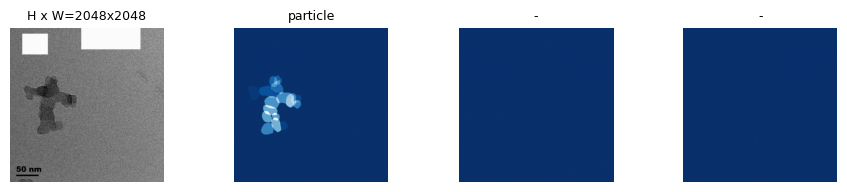


--- Dataset: Final_Valv1_norm ---
Image ID:0
Mask shape for Image ID 0: (2048, 2048, 9)
Cluster Mask shape: (0, 0, 0)
1
-1
-1


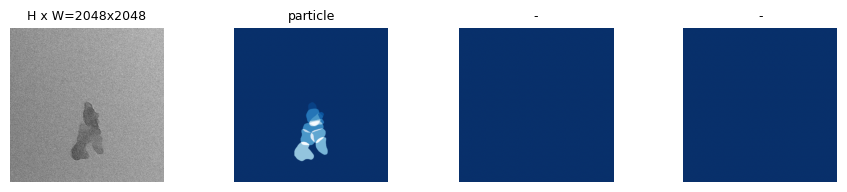

In [4]:
for name, dataset in datasets.items():
    print(f"\n--- Dataset: {name} ---")
    if len(dataset.image_ids) ==0: 
        print("No images loaded")
        continue
    image_id = dataset.image_ids[0]
    print(f"Image ID:{image_id}")
    
    image = dataset.load_image(image_id)
    mask, class_ids = dataset.load_mask(image_id)
    
    print(f"Mask shape for Image ID {image_id}: {mask.shape}")

    #Load context clusters
    cluster_masks = dataset.load_cluster_input_masks(image_id)
    print(f"Cluster Mask shape: {cluster_masks.shape}")
    visualize.display_top_masks(image, mask, class_ids, dataset.class_names, context_cluster_masks=cluster_masks, limit=4)


# 3. Training Procedure

To train a model we follow the following steps:
* 1. Model Initialization
* 2. Select datasets & configure Training Schedule
* 3. Define custom callbacks
* 4. Define augmentations
* 5. Train model through defined schedule.

## 3.1. Model Initialization 
 

First, we create a Mask R-CNN model in training mode and define starting weights

In this notebook, we perform fine-tuning initialized from SAGE<sub>0</sub> pretrained weights, using a manually specified model path.
- If training from scratch, COCO-pretrained weights (`init_with=coco`) can be used as a starting point.
- For fine-tuning SAGE<sub>0</sub> or any custom pretrained model, we use `init_with=manual`, and provide a path via `manual_path=/path/to/model.h5`
- If continuing training from a previously saved checkpoint, `init_with=last` can be used to resume training from the most recent weights.

In this workflow, we primarily use manual initialization from SAGE<sub>0</sub> weights.


In [5]:

# Create model in training mode
model = modellib.MaskRCNN(mode="training", 
                          config=config,
                          model_dir=MODEL_DIR#switch to MODEL_DIR for push
                          )


# Which weights to start with?
init_with = "manual"  # imagenet, coco, last, or manual 

#if you want to give it a specific path to train from:

manual_path = os.path.join(PRETRAIN_DIR, "SAGE_0/SAGE_0.h5")
# or manual_path = os.path.join(logs, "model_folder/model_epoch.h5") 

if init_with == "imagenet":
    model.load_weights(model.get_imagenet_weights(), by_name=True)
elif init_with == "coco":
    # Load weights trained on MS COCO, but skip layers that
    # are different due to the different number of classes
    # See README for instructions to download the COCO weights
    model.load_weights(COCO_MODEL_PATH, by_name=True,
                       exclude=["mrcnn_class_logits", "mrcnn_bbox_fc", 
                                "mrcnn_bbox", "mrcnn_mask"])
elif init_with =="manual":
    #load the weights from specified path
    model.load_weights(manual_path, 
                       by_name=True)
           

elif init_with == "last":
    # Load the last model you trained and continue training
    model.load_weights(model.find_last(), by_name=True)

Before training our model, we need to define the training and validation datasets, any custom callbacks, and the phases (stages) we want to train our model with.



## 3.2 Dataset Selection & Training Schedule

This section defines the training and validation datasets and configures the training schedule used for multi-stage training.

Datasets are selected from the previously loaded dataset registry using `datasets.get('Dataset_name')`. If needed, all datasets currently loaded can be viewed with `utils.print_loaded_datasets()`

The number of steps per epoch is automatically computed from dataset size and batch size to ensure consistent training across different dataset configurations.

The training schedule defines a sequence of training phases, where each phase specifies:
- the trainable network components (e.g., heads vs full network)
- number of epochs
- learning rate
- early stopping patience

## 3.2 Select Datasets and Configure Training Schedule

Before training the model, we must select the training and validation datasets and configure the training schedule.

Dataset are retrieved from the dataset registry using:

```python
    datasets.get(dataset_name)
```

The selected datasets are then used to automatically determine the number of training and validation steps per epoch based on the configured batch size (GPUs * images/GPU).

**Training Schedule Modes**

The `TEST` flag controls whether a short test run or a full training run is performed:
- `TEST=True`
  - Uses a small number of training and validation steps and less epochs 
  - Intended for verifying dataset loading, model initialization, memory load, and training logic.
  - Useful for quickly testing any modifications to notebook or training pipeline before launching a full training run.
- `Test=False`
  - Calculates epoch steps using selected datasets.
  - Intended for full model training



Training schedules can be defined in two ways:

**Predefined Schedules**

The recommended approach is to use the predefined default schedule provided by `SAGEConfig` using the `SCHEDULE_MODE` variable.
```python
    SCHEDULE_MODE="default"
```
Currently, the two schedules modes are `default` and `test`.

**Custom Schedules**

For experimentation, a custom training schedule can be defined directly within the notebook by setting:
```python
    USE_CUSTOM_SCHEDULE = True
```
and specifying the desired training stages, epoch counts, learning rates, and early stopping parameters for each stage.

This approach provides complete control over the training procedure without requiring modifications to the underlying configuration file.

Training schedules are defined in a list of dictionaries that define each entry in the schedule:
- `name` - Layer selection for the stage (e.g., `"heads"`, `"5+"`, `"4+"`, `"all"`).
- `epochs` - Maximum nunmber of epochs to train during stage (if early stopping is not triggered)
- `lr` - Learning rate used during that stage.
- `es_patience` - Early stopping patience, specified as the number of consecutive epochs without improving before training is stopped for that stage.  


In [6]:
#Check which datasets are loaded
utils.print_loaded_datasets(datasets)

Loaded Datasets:
- Final_Trainv1_norm
   Classes and IDs:
    ID 0: BG
    ID 1: particle
----------------------------------------
- Final_Valv1_norm
   Classes and IDs:
    ID 0: BG
    ID 1: particle
----------------------------------------


In [7]:
# ----------- Define datasets + experiment setup -----------

TEST = True
SCHEDULE_MODE = "default"   # "default" | "test"

# Optional - override predefined schedules with custom schedule
USE_CUSTOM_SCHEDULE = False

dataset_train = datasets.get("Final_Trainv1_norm", None)
dataset_val = datasets.get("Final_Valv1_norm", None)

# ----------- Step sizing (runtime-dependent, stays here) -----------

config.STEPS_PER_EPOCH = (
    2 if TEST else math.ceil(len(dataset_train.image_ids) / config.BATCH_SIZE)
)

config.VALIDATION_STEPS = (
    1 if TEST else math.ceil(len(dataset_val.image_ids) / config.BATCH_SIZE)
)

# ----------- Training schedule  -----------

if USE_CUSTOM_SCHEDULE:
    
    config.TRAIN_SCHEDULE= [
        {
            "name": "heads",
            "epochs": 100,
            "lr": config.LEARNING_RATE ,
            "es_patience": 10,
        },
        {
            "name": "5+",
            "epochs": 100,
            "lr": config.LEARNING_RATE / 10,
            "es_patience": 10
        },
        {
            "name": "all",
            "epochs": 100,
            "lr": config.LEARNING_RATE / 20,
            "es_patience": 15
        }
    ]

else:

    config.TRAIN_SCHEDULE = config.get_train_schedule(
        mode="test" if TEST else SCHEDULE_MODE
    )

In [8]:
print(model.log_dir)

/home/gventera/SAGE-fork/logs/sage20261030T1301


## 3.3 Define custom callbacks

Next, we will load any custom callbacks, either by writing in a new class of type `tf.keras.callbacks.Callback` or by calling any custom callbacks stored in the `callbacks.py` script. We have two custom callbacks we will be utilizing:

---

`1. MeanAveragePrecisionCallback()`
This calculates mAP (both VOC mAP @0.5 IoU and COCO style mAP) of an epoch against the validation dataset. 

Key inputs:
* `train_model`: model being trained
* `inference_model`: instance of model in inference mode (must create instance with batch size of 1)
* `dataset`: dataset to run mAP calculations on (validation dataset) 
* `dataset_limit`: applies a maximum count of images to calculate mAP on (will use a random subset if dataset has more than maximum count)
* `calculate_map_at_every_X_epoch`: controls how often mAP is calculated (default of 5)

**NOTE** - This callback adds significant time to training, so only use for shorter fine-tuning trainings or for debugging.

---

`2. TrainingLogger()`

Logs training configuration, tracks statistics for each epoch and stage, and stores losses and mAP values

Key inputs:
* `train_model`: model being trained
* `log_dir`: location to save log files (usually model.log_dir)
* `dataset_train`, `dataset_val`: datasets used for training and validation
* `init_with`: passes the starting weights used to initialize model
* `metric_log_cats`: what metrics or loss you want logged to csv file (`mAP`, `loss`, `general`, `all`). 

The logging categories for saving to csv (`metric_log_cats`) include the following metrics:
* `mAP`: val_AP50 and val_mAP_coco
* `loss`: loss and val_loss
* `general`: loss, val_loss, val_AP50, and val_mAP_coco
* `all`: all losses and mAP values 
    



In [9]:
#------------Custom Callbacks-----------------------

#create a model instance for inference (to be used in mAP callback)
class _InfConfig(SAGEConfig):
    NAME="SAGE"
    IMAGES_PER_GPU = 1
    GPU_COUNT = 1
    DETECTION_MIN_CONFIDENCE = 0.6
    NUM_CLASSES = 1 + 1  # background + particle + cluster
    USE_PP_HEAD = False
    PP_USE_GT_CLUSTERS = True
    PP_BYPASS_MASK_HEAD = False
    MAX_CLUSTERS = 1


model_inference = modellib.MaskRCNN(mode="inference", config=_InfConfig(),
                                    model_dir=MODEL_DIR)


#define mAP callback (full class in mrcnn.callbacks.py)
# ----- can control how often mAP is calculated with "calculate_map_at_every_X_epoch"
mean_average_precision_callback = MeanAveragePrecisionCallback(model, model_inference, dataset_val, 
                                                            calculate_map_at_every_X_epoch=1, #how often to calculate mAP (after epoch 3)
                                                            dataset_limit=50, #option to limit dataset size if validation set is quite large
                                                            log_dir = model.log_dir,
                                                            verbose=1)

#allows for config and logging of key training parameters
training_logger = TrainingLogger(model, model.log_dir, 
                                dataset_train, dataset_val,
                                init_with=init_with, #initial weights, passed from earlier
                                manual_weights_path=manual_path if init_with == "manual" else None,
                                metric_log_cats="loss",
                                verbose=1)

Instructions for updating:
Use fn_output_signature instead

[INFERENCE BUILD]
  USE_PP_HEAD           : False
  PP_USE_GT_CLUSTERS    : True
  PP_BYPASS_MASK_HEAD   : False
  -> PP Head Disabled
  -> Standard mask head only
Full config saved to YAML: /home/gventera/SAGE-fork/logs/sage20261030T1301/config.yaml
Full config saved to TXT: /home/gventera/SAGE-fork/logs/sage20261030T1301/config.txt
Training log saved to /home/gventera/SAGE-fork/logs/sage20261030T1301/training_log.yaml


## 3.4 Data Augmentation

Data augmentation can be applied during training to increase dataset variability and improve model generalization. Augmentations are applied on-the-fly during training and do not modify the original images stored in the dataset. 

The notebook provides two example augmentation pipelines. Others are available for use in `mrcnn.model`:
- Simple augmentation - Random horizontal flips
- Advanced Augmentation - Random horizontal flips, small affine transformations (rotation, scaling, and translation), and mild Gaussian noise.

The desired augmentation pipeline can be adjusted here, then later applied when calling `model.train':

```python
    model.train(
        ...,
        augmentation=augmentation_advanced
    )
```
Passing `augmentation=None` will disable augmentation original images, which also works well.

When developing or debugging the training pipeline, it is often helpful to disable augmentation. For full runs, augmentation may help improve model performance.

In [11]:
from imgaug import augmenters as iaa
from imgaug.augmenters.base import SuspiciousSingleImageShapeWarning

#option 1 - minimal 
#only horizontal flips
augmentation_simple = iaa.Fliplr(0.5)  # flip 50% of images\

#option 2 - mild/advanced 
#flips and sall rotations, scaling , mild gaussian

augmentation_advanced = iaa.Sequential([
    iaa.Fliplr(0.5), #horizontal flip 50%

    #small affine transformations (rotate, scale, translate)
    iaa.Sometimes(0.5, iaa.Affine(
        rotate=(-10, 10),
        scale=(0.95,1.05), #slight zoom in/out
        translate_percent={"x": (-0.05,0.05), "y": (-0.05,0.05)} #small shifts
    )),
    iaa.Sometimes(0.3, iaa.AdditiveGaussianNoise(scale=(0,0.01*255)))
])


# Suppress only the suspicious single image shape warning
warnings.filterwarnings(
    "ignore",
    category=SuspiciousSingleImageShapeWarning
)

## 3.5 Run training through schedule

After datasets, training schedule, custom callbacks, and augmentations are defined, models can be trained using the loop below.

This loops `model.train` through each stage of the schedule, automatically progressing to subsequent stages once epoch limit or early stopping conditions are reached.

When calling `model.train`, two arguments may need to be changed:
*  1. `custom_callbacks`: any defined callbacks can be added here, such as the `training_logger` callback defined above. Setting this to `None` will just use default callbacks

```python
            model.train(
                ...,
                custom_callbacks = [desired callbacks]
            )
```

*  2. `augmentation`: any defined augmentations may be applied here, such as `augmentation_simple` or `augmentation_advanced`. Setting this to `None` will use the original images in the dataset

```python
            model.train(
                ...,
                augmentation = [desired augmentation]
            )
```




In [12]:

# ------------------ Print full training schedule ------------------
print("Training schedule:")
print("{:<8} {:<8} {:<15} {:<10}".format("Stage", "Epochs", "Learning Rate", "ES Patience"))

for stage in config.TRAIN_SCHEDULE:
    print("{:<8} {:<8} {:<15} {:<10}".format(
        stage["name"], stage["epochs"], stage["lr"], stage.get("es_patience", "-")
    ))


total_epochs = sum(stage["epochs"] for stage in config.TRAIN_SCHEDULE)
print("\nTotal epochs:", total_epochs)
print("=" * 50)


# ---------------- Training loop --------------------

cumulative_epochs = 0

#loop through stages defined in "stages" list:
for stage in config.TRAIN_SCHEDULE:

    stage_name = stage["name"]
    stage_epochs = stage["epochs"]

    # logging state
    training_logger.stage_name = stage_name
    training_logger.scheduled_epochs = stage_epochs

    # Update config per stage
    config.LEARNING_RATE = stage["lr"]
    old_patience = config.EARLY_STOPPING_PATIENCE
    config.EARLY_STOPPING_PATIENCE = stage.get("es_patience", old_patience)

    print(f"Starting stage '{stage_name}'")
    print(f"Epochs: {stage_epochs}")
    print(f"Learning rate: {config.LEARNING_RATE}")
    print(f"ES patience: {config.EARLY_STOPPING_PATIENCE}")
    print("-" * 50)
    
    #start training
    model.train(dataset_train,dataset_val, 
            learning_rate=stage['lr'], 
            epochs=cumulative_epochs + stage_epochs, 
            layers=stage_name, 
            custom_callbacks=[mean_average_precision_callback, training_logger], #[mean_average_precision_callback, training_logger], 
            augmentation =augmentation_simple)
    
    cumulative_epochs += stage_epochs
    print("\n")
    print("=" * 50)


Training schedule:
Stage    Epochs   Learning Rate   ES Patience
heads    2        0.001           -         
all      2        0.0001          -         

Total epochs: 4
Starting stage 'heads'
Epochs: 2
Learning rate: 0.001
ES patience: 10
--------------------------------------------------

Starting at epoch 0. LR=0.001

Checkpoint Path: /home/gventera/SAGE-fork/logs/sage20261030T1301/mask_rcnn_sage_{epoch:04d}.h5
Selecting layers to train
fpn_c5p5               (Conv2D)
fpn_c4p4               (Conv2D)
fpn_c3p3               (Conv2D)
fpn_c2p2               (Conv2D)
fpn_p5                 (Conv2D)
fpn_p2                 (Conv2D)
fpn_p3                 (Conv2D)
fpn_p4                 (Conv2D)
rpn_model              (Functional)
mrcnn_mask_conv1       (TimeDistributed)
mrcnn_mask_bn1         (TimeDistributed)
mrcnn_mask_conv2       (TimeDistributed)
mrcnn_mask_bn2         (TimeDistributed)
mrcnn_class_conv1      (TimeDistributed)
mrcnn_class_bn1        (TimeDistributed)
mrcnn_mask_conv3

/home/gventera/miniforge3/envs/SAGE-gpu-env/lib/python3.10/site-packages/tensorflow/python/framework/indexed_slices.py:444: UserWarning: Converting sparse IndexedSlices(IndexedSlices(indices=Tensor("training/SGD/gradients/gradients/roi_align_classifier/concat_grad/sub:0", shape=(None,), dtype=int32), values=Tensor("training/SGD/gradients/gradients/roi_align_classifier/concat_grad/GatherV2_2:0", shape=(None, 7, 7, 256), dtype=float32), dense_shape=Tensor("training/SGD/gradients/gradients/roi_align_classifier/concat_grad/Shape:0", shape=(4,), dtype=int32))) to a dense Tensor of unknown shape. This may consume a large amount of memory.
  warnings.warn(
/home/gventera/miniforge3/envs/SAGE-gpu-env/lib/python3.10/site-packages/tensorflow/python/framework/indexed_slices.py:444: UserWarning: Converting sparse IndexedSlices(IndexedSlices(indices=Tensor("training/SGD/gradients/gradients/roi_align_classifier/concat_grad/sub_1:0", shape=(None,), dtype=int32), values=Tensor("training/SGD/gradients/

1/2 [==============>...............] - ETA: 24s - batch: 0.0000e+00 - size: 2.0000 - loss: 3.1175 - rpn_class_loss: 0.2936 - rpn_bbox_loss: 1.5566 - mrcnn_class_loss: 0.3938 - mrcnn_bbox_loss: 0.4214 - mrcnn_mask_loss: 0.4521

2026-10-30 13:17:18.210871: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:135] cuptiGetTimestamp: error 999: 
2026-10-30 13:17:18.210930: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:184] cuptiSubscribe: ignored due to a previous error.
2026-10-30 13:17:18.210937: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:457] cuptiGetResultString: ignored due to a previous error.
2026-10-30 13:17:18.210943: E tensorflow/core/profiler/backends/gpu/cupti_tracer.cc:1715] function cupti_interface_->Subscribe( &subscriber_, (CUpti_CallbackFunc)ApiCallback, this)failed with error 


2/2 [==============================] - ETA: 0s - batch: 0.5000 - size: 2.0000 - loss: 3.1938 - rpn_class_loss: 0.3080 - rpn_bbox_loss: 1.3259 - mrcnn_class_loss: 0.6316 - mrcnn_bbox_loss: 0.4515 - mrcnn_mask_loss: 0.4768     

2026-10-30 13:17:20.641189: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:140] cuptiFinalize: ignored due to a previous error.
2026-10-30 13:17:20.641222: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:457] cuptiGetResultString: ignored due to a previous error.
2026-10-30 13:17:20.641229: E tensorflow/core/profiler/backends/gpu/cupti_tracer.cc:1807] function cupti_interface_->Finalize()failed with error 
2026-10-30 13:17:20.665659: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:133] cuptiGetTimestamp: ignored due to a previous error.
2026-10-30 13:17:20.665682: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:133] cuptiGetTimestamp: ignored due to a previous error.


... (3 outputs left out)

2026-10-30 13:24:31.762688: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:133] cuptiGetTimestamp: ignored due to a previous error.
2026-10-30 13:24:31.762735: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:184] cuptiSubscribe: ignored due to a previous error.
2026-10-30 13:24:31.762741: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:457] cuptiGetResultString: ignored due to a previous error.
2026-10-30 13:24:31.762747: E tensorflow/core/profiler/backends/gpu/cupti_tracer.cc:1715] function cupti_interface_->Subscribe( &subscriber_, (CUpti_CallbackFunc)ApiCallback, this)failed with error 


2/2 [==============================] - ETA: 0s - batch: 0.5000 - size: 2.0000 - loss: 5.6012 - rpn_class_loss: 0.2519 - rpn_bbox_loss: 0.8806 - mrcnn_class_loss: 0.7426 - mrcnn_bbox_loss: 0.4617 - mrcnn_mask_loss: 0.4639     

2026-10-30 13:24:35.262566: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:140] cuptiFinalize: ignored due to a previous error.
2026-10-30 13:24:35.262597: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:457] cuptiGetResultString: ignored due to a previous error.
2026-10-30 13:24:35.262603: E tensorflow/core/profiler/backends/gpu/cupti_tracer.cc:1807] function cupti_interface_->Finalize()failed with error 
2026-10-30 13:24:35.317014: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:133] cuptiGetTimestamp: ignored due to a previous error.
2026-10-30 13:24:35.317043: E tensorflow/core/profiler/backends/gpu/cupti_error_manager.cc:133] cuptiGetTimestamp: ignored due to a previous error.


Calculating mAP...
Inference model expects inputs:

[INFERENCE BUILD]
  USE_PP_HEAD           : False
  PP_USE_GT_CLUSTERS    : True
  PP_BYPASS_MASK_HEAD   : False
  -> PP Head Disabled
  -> Standard mask head only
Re-starting from epoch 3
Inference model rebuilt and weights loaded cleanly.
Updating logs with mAP results
mean AP50 at epoch 3 is: 0.35594234602334995
mAP COCO at epoch 3 is: 0.12827040306742588
2/2 [==============================] - 120s 99s/step - batch: 0.5000 - size: 2.0000 - loss: 5.6012 - rpn_class_loss: 0.2519 - rpn_bbox_loss: 0.8806 - mrcnn_class_loss: 0.7426 - mrcnn_bbox_loss: 0.4617 - mrcnn_mask_loss: 0.4639 - val_loss: 5.2122 - val_rpn_class_loss: 0.1357 - val_rpn_bbox_loss: 0.7385 - val_mrcnn_class_loss: 0.7899 - val_mrcnn_bbox_loss: 0.4888 - val_mrcnn_mask_loss: 0.4531 - val_AP50: 0.3559 - val_mAP_coco: 0.1283
Epoch 4/4
2/2 [==============================] - ETA: 0s - batch: 0.5000 - size: 2.0000 - loss: 4.4622 - rpn_class_loss: 0.1351 - rpn_bbox_loss: 0.6517

In [13]:
print("DONE")

DONE


# 4. Fine-tuning on Manual Images - Future implementation (Full Pipeline with SAGE<sub>0</sub> Training)

This section describes the full intended training pipeline, which includes SAGE<sub>0</sub> pretraining (using synthetic data) followed by sequential fine-tuning on manually annotated TEM data.

In the full pipeline:
- SAGE<sub>0</sub> is trained on synthetic TEM image (not currently included in this release), initialized with COCO weights (`init_with=coco`)
- The resulting weights are used to initialize subsequent models for fine-tuning

Starting from SAGE<sub>0</sub> weights, we can initialize a new model and train on manually annotaed real TEM images to improve performance.

This follows the same training procesdure as earlier sections, differing only in initalization weights and dataset selection. 

- Using `init_with=manual` (set to SAGE<sub>0</sub> model path) or `init_with=last` if SAGE<sub>0</sub> was the most recetly trained model, and training on `M1_train` and `M1_val` produces SAGE<sub>1</sub>
- Repeating the process (initialized with SAGE<sub>1</sub> weights) produces SAGE<sub>2</sub>
- Initializing with SAGE<sub>0</sub> weights and training on the larger, more diverse `Final_Trainv1` and `Final_Valv1` datasets produces SAGE<sub>1-exp</sub>
- Similarly, fine-tuning SAGE<sub>0</sub> with the scale-normalized `Final_Trainv1_norm` and `Final_Valv1_norm` produces SAGE<sub>1-exp-N</sub>

In the current notebook implementation, SAGE<sub>0</sub> is pre-trained externally and loaded from a github release.


In [ ]:
"""

#--------- Create NEW model in training mode ------------
model = modellib.MaskRCNN(mode="training", config=config,
                          model_dir=MODEL_DIR)

#--------Load starting weights (from either last model or a defined path)
init_with = "last"  # last or manual
manual_path

if init_with =="manual":
    #load the weights from specified path
    model.load_weights(manual_path, by_name=True)

elif init_with == "last":
    # Load the last model you trained and continue training
    model.load_weights(model.find_last(), by_name=True)

#--------Assign new train/val datasets---------
dataset_train = datasets.get('D1e1_train', None)
dataset_val = datasets.get('D1e1_val', None)

#Adjust step sizes based on batch size
config.STEPS_PER_EPOCH = math.ceil(len(dataset_train.image_ids) / config.BATCH_SIZE)
config.VALIDATION_STEPS = math.ceil(len(dataset_val.image_ids) / config.BATCH_SIZE)

#------------Redefine Custom Callbacks-----------------------

#create a model instance for inference (to be used in mAP callback)
class _InfConfig(Config):
    NAME="SAGE"
    IMAGES_PER_GPU = 1
    GPU_COUNT = 1
    DETECTION_MIN_CONFIDENCE = 0.7
    NUM_CLASSES = 1 + 1  # background + particle + cluster

model_inference = modellib.MaskRCNN(mode="inference", config=_InfConfig(),
                                    model_dir=MODEL_DIR)


#define mAP callback (full class in mrcnn.callbacks.py)
# ----- can control how often mAP is calculated with "calculate_map_at_every_X_epoch"
mean_average_precision_callback = MeanAveragePrecisionCallback(model, model_inference, dataset_val, 
                                                            calculate_map_at_every_X_epoch=1, #how often to calculate mAP (after epoch 3)
                                                            dataset_limit=50, #option to limit dataset size if validation set is quite large
                                                            verbose=1)

#allows for config and logging of key training parameters
training_logger = TrainingLogger(model, model.log_dir, 
                                dataset_train, dataset_val,
                                init_with=init_with, #initial weights, passed from earlier
                                manual_weights_path=manual_path if init_with == "manual" else None,
                                metric_log_cats="general",
                                verbose=1)

#---Degine new training schedule and train
train_schedule = [
    {"name": "heads", "epochs": 100, "learning_rate": config.LEARNING_RATE},
    {"name": "all", "epochs": 100, "learning_rate": config.LEARNING_RATE/10}
]

total_epochs = sum(stage["epochs"] for stage in train_schedule)
cumulative_epochs = 0

#loop through stages defined in "stages" list:
for stage in train_schedule:
    stage_name = stage["name"]
    stage_epochs = stage["epochs"]

    training_logger.stage_name = stage_name
    training_logger.scheduled_epochs = stage_epochs
    
    #start training
    model.train(dataset_train,dataset_val, 
            learning_rate=stage['learning_rate'], 
            epochs=cumulative_epochs + stage_epochs, 
            layers=stage_name, custom_callbacks=[mean_average_precision_callback, training_logger])
    
    cumulative_epochs += stage_epochs

"""